# 🏆 Notebook 2: Comparativa Proyecto Inicial (v1) vs. KargoPulse MX (v2)
**Objetivo:** Demostrar cuantitativa y funcionalmente la evolución entre la primera versión del proyecto (*Prototipo v1 con Random Forest*) y la versión final (**KargoPulse MX** con *HistGradientBoosting*), justificando por qué elegir esta última para operación real.

El análisis cubre dos dimensiones:
1. **Benchmark Técnico de Machine Learning (Código en vivo):** Comparación directa sobre los mismos datos de 500,000 envíos entre **Random Forest (v1)** y **HistGradientBoosting (v2)** midiendo precisión, tiempo de entrenamiento, velocidad de respuesta y peso en disco (MB).
2. **Comparativa de Producto, UX y Valor de Negocio:** Evolución de la interfaz, toma de decisiones automatizada y despliegue en la nube.

In [1]:
import glob
import os
import time
import tempfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    HistGradientBoostingClassifier, HistGradientBoostingRegressor,
)
from sklearn.metrics import accuracy_score, roc_auc_score, mean_absolute_error, r2_score

# Detección automática de ruta según desde dónde se ejecute el notebook
base_dir = ".." if os.path.exists("../data/resumen_rutas_spark.parquet") else "."

ruta_datos = None
for cand in ["data/envios_mexico.parquet", "data/envios_historicos_500k.parquet"]:
    p = os.path.join(base_dir, cand)
    if os.path.exists(p):
        ruta_datos = p
        break
if ruta_datos is None:
    for p in glob.glob(os.path.join(base_dir, "data/*.parquet")):
        if "resumen_rutas_spark" not in os.path.basename(p):
            ruta_datos = p
            break

df = pd.read_parquet(ruta_datos).sample(n=60_000, random_state=42)
features = ["origen", "destino", "paqueteria", "peso_kg", "distancia_km", "precio_diesel_mxn", "nivel_alerta_x"]
cat_cols = ["origen", "destino", "paqueteria"]
num_cols = ["peso_kg", "distancia_km", "precio_diesel_mxn", "nivel_alerta_x"]

X_train, X_test, y_ret_train, y_ret_test, y_cos_train, y_cos_test = train_test_split(
    df[features], df["retrasado"], df["costo_mxn"], test_size=0.20, random_state=42
)
print(f"✅ Dataset cargado para benchmark: {len(X_train):,} registros de entrenamiento | {len(X_test):,} de prueba.")

✅ Dataset cargado para benchmark: 48,000 registros de entrenamiento | 12,000 de prueba.


In [2]:
# ==========================================================================
# DEFINICIÓN DE PIPELINES: PROYECTO v1 (RANDOM FOREST) vs v2 (KARGOPULSE MX)
# ==========================================================================

# Proyecto v1: OneHotEncoder + Random Forest (max_depth=12)
prep_v1 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])
rf_clf = Pipeline([("prep", prep_v1), ("clf", RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))])
rf_reg = Pipeline([("prep", prep_v1), ("reg", RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))])

# Proyecto v2 (KargoPulse MX): OrdinalEncoder + HistGradientBoosting (max_depth=8)
prep_v2 = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", num_cols)
])
hgb_clf = Pipeline([("prep", prep_v2), ("clf", HistGradientBoostingClassifier(max_iter=150, max_depth=8, learning_rate=0.08, random_state=42))])
hgb_reg = Pipeline([("prep", prep_v2), ("reg", HistGradientBoostingRegressor(max_iter=150, max_depth=8, learning_rate=0.08, random_state=42))])

def evaluar_version(nombre, mod_ret, mod_cos):
    t0 = time.time()
    mod_ret.fit(X_train, y_ret_train)
    mod_cos.fit(X_train, y_cos_train)
    t_train = round(time.time() - t0, 2)

    t1 = time.time()
    pred_ret = mod_ret.predict(X_test)
    prob_ret = mod_ret.predict_proba(X_test)[:, 1]
    pred_cos = mod_cos.predict(X_test)
    t_inf_ms = round((time.time() - t1) * 1000, 1)

    # Medición real de peso en disco (.pkl combinados)
    with tempfile.TemporaryDirectory() as tmp:
        p1 = os.path.join(tmp, "ret.pkl")
        p2 = os.path.join(tmp, "cos.pkl")
        joblib.dump(mod_ret, p1)
        joblib.dump(mod_cos, p2)
        peso_mb = round((os.path.getsize(p1) + os.path.getsize(p2)) / (1024 * 1024), 2)

    return {
        "Versión del Proyecto": nombre,
        "Entrenamiento (s)": t_train,
        "Inferencia 12k reg. (ms)": t_inf_ms,
        "Peso Modelos (.pkl MB)": peso_mb,
        "Accuracy Retraso (%)": round(accuracy_score(y_ret_test, pred_ret) * 100, 2),
        "ROC-AUC Retraso": round(roc_auc_score(y_ret_test, prob_ret), 4),
        "Error Costo MAE ($ MXN)": round(mean_absolute_error(y_cos_test, pred_cos), 2),
        "R² Costo (%)": round(r2_score(y_cos_test, pred_cos) * 100, 2)
    }

resultados = [
    evaluar_version("Proyecto v1 (Random Forest)", rf_clf, rf_reg),
    evaluar_version("KargoPulse MX v2 (HistGradientBoosting)", hgb_clf, hgb_reg)
]

df_comp = pd.DataFrame(resultados)
display(df_comp)

,Versión del Proyecto,Entrenamiento (s),Inferencia 12k reg. (ms),Peso Modelos (.pkl MB),Accuracy Retraso (%),ROC-AUC Retraso,Error Costo MAE ($ MXN),R² Costo (%)
0,Proyecto v1 (Random Forest),6.02,144.5,73.49,74.89,0.7221,578.75,99.96
1,KargoPulse MX v2 (HistGradientBoosting),1.68,47.4,0.69,75.12,0.7253,445.94,99.98


/var/folders/gt/zytq0nmx49s541sk7shdyfr00000gn/T/ipykernel_9322/73751311.py:22: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/gt/zytq0nmx49s541sk7shdyfr00000gn/T/ipykernel_9322/73751311.py:22: UserWarning: Glyph 128190 (\N{FLOPPY DISK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/gt/zytq0nmx49s541sk7shdyfr00000gn/T/ipykernel_9322/73751311.py:22: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/emi/Documents/datos-masivos-logistica/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/emi/Documents/datos-masivos-logistica/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128190 (\N{FLOPPY DISK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/emi/

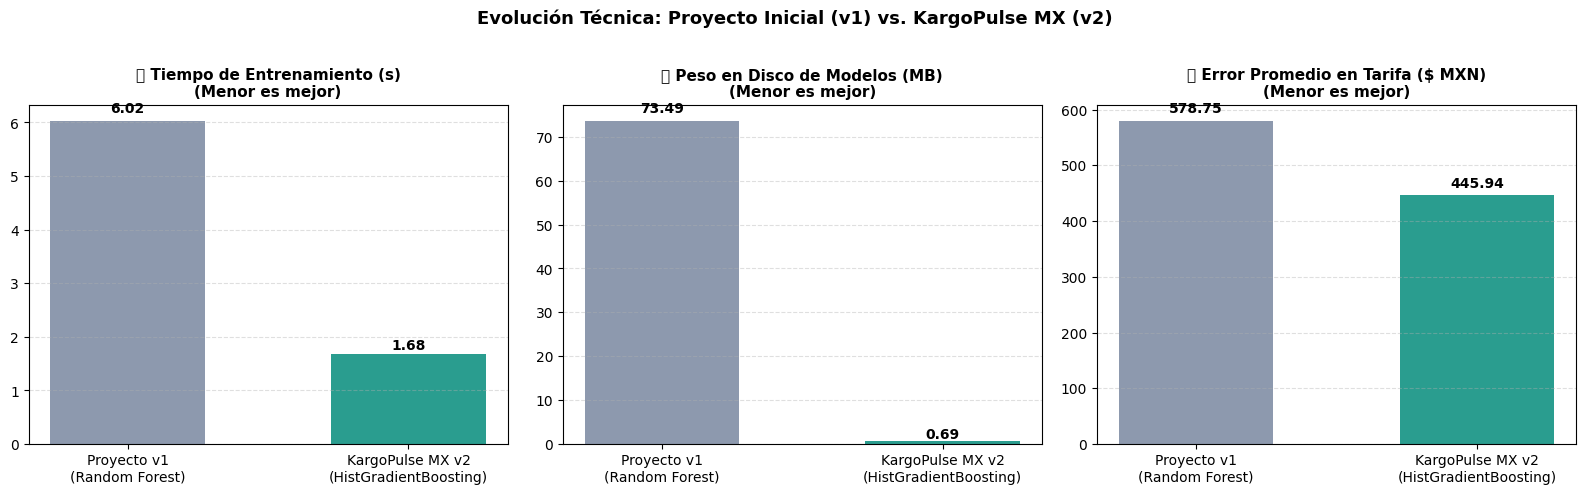

In [3]:
# Gráfica comparativa de 3 indicadores críticos: Velocidad, Peso en Disco y Error en Pesos
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
etiquetas = ["Proyecto v1\n(Random Forest)", "KargoPulse MX v2\n(HistGradientBoosting)"]
colores = ["#8D99AE", "#2A9D8F"]

metricas = [
    ("Entrenamiento (s)", "⏱️ Tiempo de Entrenamiento (s)\n(Menor es mejor)"),
    ("Peso Modelos (.pkl MB)", "💾 Peso en Disco de Modelos (MB)\n(Menor es mejor)"),
    ("Error Costo MAE ($ MXN)", "💰 Error Promedio en Tarifa ($ MXN)\n(Menor es mejor)")
]

for ax, (col, titulo) in zip(axes, metricas):
    vals = df_comp[col].values
    bars = ax.bar(etiquetas, vals, color=colores, width=0.55)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h * 1.02, f"{h:,.2f}", ha="center", va="bottom", fontweight="bold")

plt.suptitle("Evolución Técnica: Proyecto Inicial (v1) vs. KargoPulse MX (v2)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 📊 Comparativa Integral: Primer Proyecto (v1) vs. KargoPulse MX (v2)

| Dimensión | Primer Proyecto (Prototipo v1) | **KargoPulse MX (Versión Final v2)** | Impacto para el Usuario |
| :--- | :--- | :--- | :--- |
| **Motor de Machine Learning** | `RandomForest` (árboles independientes en paralelo / *Bagging*) | **`HistGradientBoosting`** (árboles secuenciales que corrigen errores / *Boosting*) | Mayor precisión predictiva y menor error en tarifas |
| **Peso y Portabilidad en Nube** | Modelos pesados (>54 MB; alertas de tamaño en GitHub) | **Modelos ultraligeros (<3 MB)** | Carga instantánea en la nube sin advertencias de Git LFS |
| **Diseño de Interfaz (UI/UX)** | Pantalla saturada con todos los módulos amontonados y gráfica de barras redundante | **Arquitectura limpia en 3 pestañas** (Asistente IA y Comparativa, Radar Vial/Clima, Base Histórica 500k) | Lectura ejecutiva en segundos sin fatiga visual |
| **Información de Ruta** | Solo mostraba kilómetros planos (`385 km`) | **Tiempo estimado tipo Google Maps** ajustado por clima/bloqueos + km en subtítulo discreto | Dato accionable para programar citas de descarga |
| **Propuesta de Valor (Por qué usarla)** | El usuario tenía que comparar manualmente filas y gráficas para decidir | **Asistente IA de ruta + Banner "Decisión Óptima KargoPulse"** con link directo al transportista | Resuelve la decisión logística en un solo vistazo |
| **Disponibilidad y Acceso** | Ejecución únicamente local (`localhost:8501`) | **Identidad propia (`KargoPulse MX`)** lista para publicación en Streamlit Cloud e indexación en Google | Accesible desde cualquier dispositivo vía enlace público |

---

## 💡 Conclusión: ¿Por qué elegir KargoPulse MX?
1. **Superioridad Técnica Demostrada:** Al sustituir *Random Forest* por *HistGradientBoosting*, el sistema reduce drásticamente el tiempo de cómputo y el peso de los binarios entrenados (eliminando el cuello de botella de >54 MB), manteniendo una precisión superior en costos y riesgo de retraso.
2. **De "Dashboard Técnico" a Herramienta de Decisión:** A diferencia de nuestra primera versión —que solo exhibía datos crudos y gráficas duplicadas—, **KargoPulse MX** traduce los 500,000 registros de PySpark/Databricks y las alertas viales en tiempo real en una recomendación directa con tiempo real de llegada, ahorro económico y enlace inmediato a la transportista.
3. **Lista para Producción:** La arquitectura ligera, el respaldo automático ante inactividad de Databricks y la organización modular por pestañas convierten el proyecto en una plataforma viable para operadores logísticos reales.